In [ ]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("Neo4j", "neo4jaya")

In [9]:
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
AUTH = ("neo4j", "neo4jaya")

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")
except Exception as e:
    print("Koneksi gagal:", e)
finally:
    driver.close()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4876\1281146365.py:9: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi Neo4j berhasil!


In [13]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name,
            friend_name=friend_name
        )

In [14]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Data berhasil ditambahkan!")

Data berhasil ditambahkan!


1. data base yang digunakan dalam tutorial tersebut adalah neo4j
2. untuk mengakses database lain dapat menggunakan query "USE <nama_database>"
3. dan untuk graph yang digunakan merupakan graf berarah yang ditandakan dengan adanya panah(->)

***1.3***

In [2]:
from neo4j import GraphDatabase

uri = "neo4j://127.0.0.1:7687"  
user = "neo4j"
password = "neo4jaya"
driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="neo4j")  

In [3]:
import argparse


def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4j."
    )
    parser.add_argument(
        "-u",
        "--user",
        default="neo4j",
        help="Username Neo4j (default: neo4j)",
    )
    parser.add_argument(
        "-p",
        "--password",
        default="neo4jaya", 
        help="Password Neo4j (default: neo4jaya)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4j URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    return parser.parse_args()

In [6]:

import os
import sys
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

# 1. Fungsi import batch
def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row
    MERGE (e:Event {event_index: row.event_index})
    SET e.timestamp = row.timestamp,
        e.visitorid = row.visitorid,
        e.event = row.event,
        e.itemid = row.itemid,
        e.transactionid = row.transactionid
    """
    tx.run(query, batch=batch)

# 2. Path file CSV
csv_file_path = r"C:\Users\Lenovo\.Neo4jDesktop2\Data\dbmss\dbms-22abc53f-011a-4924-8818-c15818d5eb55\events.csv"

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

# 3. Koneksi Neo4j
try:
    uri = "bolt://127.0.0.1:7687"
    user = "neo4j"
    password = "neo4jaya"

    driver = GraphDatabase.driver(uri, auth=(user, password))
    driver.verify_connectivity()

    print("Berhasil terhubung ke database Neo4j.")

except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

# 4. Proses impor data menggunakan batch
batch_size = 10000

try:
    with driver.session(database="neo4j") as session:

        print(f"Membaca file data dari: {csv_file_path}")

        chunks = pd.read_csv(
            csv_file_path,
            chunksize=batch_size
        )

        print("Memulai proses impor data ke Neo4j...")

        for i, chunk in enumerate(
            tqdm(chunks, desc="Mengimpor Batch Data")
        ):

            # Membuat ID unik berdasarkan nomor baris
            chunk["event_index"] = range(
                i * batch_size,
                i * batch_size + len(chunk)
            )

            # Membersihkan data kosong
            chunk["transactionid"] = (
                chunk["transactionid"].fillna("").astype(str)
            )

            chunk["itemid"] = (
                chunk["itemid"].fillna(0).astype(int)
            )

            chunk["visitorid"] = (
                chunk["visitorid"].fillna(0).astype(int)
            )

            # Mengubah DataFrame menjadi dictionary
            records = chunk.to_dict(orient="records")

            if records:
                session.execute_write(import_batch, records)

    print("Proses impor berhasil!")

except Exception as e:
    print(f"Terjadi kesalahan saat impor: {e}")

finally:
    driver.close()


Berhasil terhubung ke database Neo4j.
Membaca file data dari: C:\Users\Lenovo\.Neo4jDesktop2\Data\dbmss\dbms-22abc53f-011a-4924-8818-c15818d5eb55\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 1it [20:23, 1223.26s/it][#F009]  _: <CONNECTION> error: Failed to read from defunct connection IPv4Address(('127.0.0.1', 7687)) (ResolvedIPv4Address(('127.0.0.1', 7687))): TimeoutError('timed out')
Transaction failed and will be retried in 1.0637688074676568s (Failed to read from defunct connection IPv4Address(('127.0.0.1', 7687)) (ResolvedIPv4Address(('127.0.0.1', 7687))))
Mengimpor Batch Data: 1it [26:56, 1616.85s/it]


Terjadi kesalahan saat impor: Couldn't connect to 127.0.0.1:7687 (resolved to ('127.0.0.1:7687',)):
Failed to read four byte Bolt handshake response from server ResolvedIPv4Address(('127.0.0.1', 7687)) (deadline Deadline(timeout=60.0))


In [7]:

import os
import sys
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

# ==================================================
# 1. KONFIGURASI
# ==================================================

CSV_FILE_PATH = r"C:\Users\Lenovo\.Neo4jDesktop2\Data\dbmss\dbms-22abc53f-011a-4924-8818-c15818d5eb55\events.csv"

NEO4J_URI = "bolt://127.0.0.1:7687"
NEO4J_USER = "neo4j"
NEO4J_PASSWORD = "neo4jaya"
DATABASE_NAME = "neo4j"

# Ukuran setiap batch
BATCH_SIZE = 1000

# Kolom dataset Retailrocket
REQUIRED_COLUMNS = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid"
]

NUMERIC_COLUMNS = [
    "timestamp",
    "visitorid",
    "itemid",
    "transactionid"
]


# ==================================================
# 2. FUNGSI MEMBERSIHKAN DATA
# ==================================================

def clean_value(value):

    if pd.isna(value):
        return None

    return str(value)


def clean_integer(value):

    if pd.isna(value):
        return None

    return int(value)


# ==================================================
# 3. FUNGSI IMPORT DATA KE NEO4J
# ==================================================

def import_batch(tx, batch):

    query = """
    UNWIND $batch AS row

    MERGE (e:Event {event_index: row.event_index})

    SET
        e.timestamp = row.timestamp,
        e.visitorid = row.visitorid,
        e.event = row.event,
        e.itemid = row.itemid,
        e.transactionid = row.transactionid

    """

    result = tx.run(query, batch=batch)

    # Memastikan transaksi selesai diproses
    result.consume()


# ==================================================
# 4. CEK FILE CSV
# ==================================================

print("=" * 55)
print("PERSIAPAN IMPORT DATA RETAILROCKET")
print("=" * 55)

if not os.path.exists(CSV_FILE_PATH):

    print("ERROR: File CSV tidak ditemukan!")
    sys.exit(1)

print("File CSV ditemukan.")

# ==================================================
# 5. MEMBUAT KONEKSI NEO4J
# ==================================================

try:

    driver = GraphDatabase.driver(
        NEO4J_URI,
        auth=(NEO4J_USER, NEO4J_PASSWORD),
        connection_timeout=30,
        max_transaction_retry_time=120,
        max_connection_lifetime=3600
    )

    driver.verify_connectivity()

    print("Berhasil terhubung ke Neo4j.")
    print("Database:", DATABASE_NAME)
    print("URI:", NEO4J_URI)

except Exception as e:

    print("Gagal menghubungkan Neo4j:")
    print(e)

    sys.exit(1)


# ==================================================
# 6. PROSES IMPORT DATA
# ==================================================

try:

    with driver.session(database=DATABASE_NAME) as session:

        # ------------------------------------------
        # 6.1 Memeriksa jumlah data sebelumnya
        # ------------------------------------------

        existing = session.run("""
            MATCH (e:Event)
            RETURN count(e) AS total
        """).single()

        print(
            "Event yang sudah ada:",
            existing["total"]
        )

        # ------------------------------------------
        # 6.2 Membuat constraint unik
        # ------------------------------------------

        session.run("""
            CREATE CONSTRAINT event_index_unique
            IF NOT EXISTS
            FOR (e:Event)
            REQUIRE e.event_index IS UNIQUE
        """).consume()

        print("Constraint event_index siap.")

        # ------------------------------------------
        # 6.3 Membaca CSV per batch
        # ------------------------------------------

        print("\nMembaca dataset Retailrocket...")

        chunks = pd.read_csv(
            CSV_FILE_PATH,
            chunksize=BATCH_SIZE,
            low_memory=False
        )

        total_imported = 0
        batch_number = 0

        print("\nMemulai proses import data...\n")

        # ------------------------------------------
        # 6.4 Import setiap batch
        # ------------------------------------------

        for batch_number, chunk in enumerate(
            tqdm(chunks, desc="Import Event"),
            start=1
        ):

            # Memastikan kolom sesuai
            missing_columns = [
                col for col in REQUIRED_COLUMNS
                if col not in chunk.columns
            ]

            if missing_columns:
                raise ValueError(
                    f"Kolom CSV tidak ditemukan: {missing_columns}"
                )

            # Membuat ID berdasarkan nomor baris
            start_index = (batch_number - 1) * BATCH_SIZE

            chunk["event_index"] = range(
                start_index,
                start_index + len(chunk)
            )

            # Mengubah kolom numerik
            for col in NUMERIC_COLUMNS:

                chunk[col] = pd.to_numeric(
                    chunk[col],
                    errors="coerce"
                ).astype("Int64")

            # Mengubah event menjadi string
            chunk["event"] = chunk["event"].astype("string")

            # --------------------------------------
            # Mengubah DataFrame menjadi dictionary
            # --------------------------------------

            records = chunk.to_dict(orient="records")

            # Membersihkan nilai setiap baris
            for row in records:

                row["event_index"] = int(
                    row["event_index"]
                )

                for col in NUMERIC_COLUMNS:

                    row[col] = clean_integer(row[col])

                row["event"] = clean_value(
                    row["event"]
                )

            # --------------------------------------
            # Mengirim batch ke Neo4j
            # --------------------------------------

            if records:

                session.execute_write(
                    import_batch,
                    records
                )

                total_imported += len(records)

            # Menampilkan progres
            tqdm.write(
                f"Batch {batch_number} selesai | "
                f"Total diproses: {total_imported:,} baris"
            )

        # ------------------------------------------
        # 6.5 Menghitung hasil akhir
        # ------------------------------------------

        result = session.run("""
            MATCH (e:Event)
            RETURN count(e) AS total
        """).single()

        final_total = result["total"]

        print("\n" + "=" * 55)
        print("IMPORT DATA SELESAI!")
        print("=" * 55)

        print("Batch berhasil diproses:", batch_number)
        print("Baris diproses:", f"{total_imported:,}")
        print("Total Event di Neo4j:", f"{final_total:,}")

except Exception as e:

    print("\n" + "=" * 55)
    print("IMPORT DATA MENGALAMI KESALAHAN")
    print("=" * 55)

    print("Pesan error:", str(e))

    print(
        "\nData yang sudah berhasil masuk "
        "tetap tersimpan."
    )

    print(
        "Periksa penyebab error sebelum "
        "menjalankan ulang."
    )

finally:

    driver.close()

    print("\nKoneksi Neo4j ditutup.")


PERSIAPAN IMPORT DATA RETAILROCKET
File CSV ditemukan.
Berhasil terhubung ke Neo4j.
Database: neo4j
URI: bolt://127.0.0.1:7687
Event yang sudah ada: 144000
Constraint event_index siap.

Membaca dataset Retailrocket...

Memulai proses import data...



Import Event: 1it [00:19, 19.18s/it]

Batch 1 selesai | Total diproses: 1,000 baris


Import Event: 2it [00:19,  8.37s/it]

Batch 2 selesai | Total diproses: 2,000 baris


...

Batch 2756 selesai | Total diproses: 2,756,000 baris


Import Event: 2757it [21:35,  2.53it/s]

Batch 2757 selesai | Total diproses: 2,756,101 baris


Import Event: 2757it [21:35,  2.13it/s]



IMPORT DATA SELESAI!
Batch berhasil diproses: 2757
Baris diproses: 2,756,101
Total Event di Neo4j: 2,756,101

Koneksi Neo4j ditutup.


In [15]:

from neo4j import GraphDatabase
from tqdm import tqdm

# ==========================================
# 1. KONEKSI NEO4J
# ==========================================

URI = "bolt://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = "neo4jaya"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD),
    connection_timeout=30,
    max_transaction_retry_time=120
)

driver.verify_connectivity()

print("Berhasil terhubung ke Neo4j!")


# ==========================================
# 2. FUNGSI MEMBUAT GRAF
# ==========================================


def import_batch(tx, batch):

    query = """

    UNWIND $batch AS row

    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})

    FOREACH (_ IN CASE
        WHEN row.event = 'view' THEN [1]
        ELSE []
    END |

        MERGE (v)-[r:VIEWED {
            event_index: row.event_index
        }]->(i)

        SET r.timestamp = row.timestamp
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'addtocart' THEN [1]
        ELSE []
    END |

        MERGE (v)-[r:ADDED_TO_CART {
            event_index: row.event_index
        }]->(i)

        SET r.timestamp = row.timestamp
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'transaction' THEN [1]
        ELSE []
    END |

        MERGE (v)-[r:BOUGHT {
            event_index: row.event_index
        }]->(i)

        SET r.timestamp = row.timestamp,
            r.transactionid = row.transactionid
    )

    """

    tx.run(query, batch=batch).consume()

# ==========================================
# 3. PERSIAPAN CONSTRAINT
# ==========================================

try:

    with driver.session(database="neo4j") as session:

        session.run("""
            CREATE CONSTRAINT visitor_id_unique
            IF NOT EXISTS
            FOR (v:Visitor)
            REQUIRE v.visitorid IS UNIQUE
        """).consume()

        session.run("""
            CREATE CONSTRAINT item_id_unique
            IF NOT EXISTS
            FOR (i:Item)
            REQUIRE i.itemid IS UNIQUE
        """).consume()

        print("Constraint berhasil diperiksa.")

        # ======================================
        # 4. MENGHITUNG DATA EVENT
        # ======================================

        total_result = session.run("""
            MATCH (e:Event)
            RETURN count(e) AS total
        """).single()

        total_events = total_result["total"]

        print("Total Event:", f"{total_events:,}")
        print("Memulai konversi Event menjadi graf...")

        # ======================================
        # 5. PROSES BATCH DARI NEO4J
        # ======================================

        BATCH_SIZE = 1000
        last_id = -1
        total_processed = 0

        with tqdm(
            total=total_events,
            desc="Membuat Graf Retailrocket"
        ) as progress:

            while True:

                # Mengambil data langsung dari Neo4j
                records = session.run("""
                    MATCH (e:Event)

                    WHERE e.event_index > $last_id
                      AND e.visitorid IS NOT NULL
                      AND e.itemid IS NOT NULL
                      AND e.event IN [
                          'view',
                          'addtocart',
                          'transaction'
                      ]

                    RETURN
                        e.event_index AS event_index,
                        e.timestamp AS timestamp,
                        e.visitorid AS visitorid,
                        e.event AS event,
                        e.itemid AS itemid,
                        e.transactionid AS transactionid

                    ORDER BY e.event_index
                    LIMIT $batch_size

                """,
                    last_id=last_id,
                    batch_size=BATCH_SIZE
                ).data()

                if not records:
                    break

                # Mengirim data untuk membuat relasi
                session.execute_write(
                    import_batch,
                    records
                )

                # Memperbarui posisi terakhir
                last_id = records[-1]["event_index"]

                total_processed += len(records)

                progress.update(len(records))

        # ======================================
        # 6. HASIL AKHIR
        # ======================================

        print("\nPROSES KONVERSI SELESAI!")

        result = session.run("""
            MATCH (v:Visitor)
            WITH count(v) AS visitors

            MATCH (i:Item)
            WITH visitors, count(i) AS items

            OPTIONAL MATCH ()-[r]->()

            RETURN
                visitors,
                items,
                count(r) AS relationships

        """).single()

        print("Total Visitor:",
              f"{result['visitors']:,}")

        print("Total Item:",
              f"{result['items']:,}")

        print("Total Relationship:",
              f"{result['relationships']:,}")

        print("Total Event diproses:",
              f"{total_processed:,}")

except Exception as e:

    print("\nTerjadi kesalahan:")
    print(e)

finally:

    driver.close()
    print("Koneksi Neo4j ditutup.")


Berhasil terhubung ke Neo4j!
Constraint berhasil diperiksa.
Total Event: 2,756,101
Memulai konversi Event menjadi graf...


Membuat Graf Retailrocket: 100%|██████████| 2756101/2756101 [1:26:20<00:00, 531.99it/s] 



PROSES KONVERSI SELESAI!
Total Visitor: 1,407,580
Total Item: 235,061
Total Relationship: 2,756,101
Total Event diproses: 2,756,101
Koneksi Neo4j ditutup.


# 2.1

In [16]:
%pip install pandas numpy scipy scikit-learn matplotlib networkx neo4j tqdm


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/41.3 MB ? eta -:--:--
   - -------------------------------------- 1.6/41.3 MB 8.3 MB/s eta 0:00:05
   --- ------------------------------------ 3.9/41.3 MB 7.1 MB/s eta 0:00:06
   ----- ---------------------------------- 5.5/41.3 MB 7.0 MB/s eta 0:00:06
   ------ --------------------------------- 6.8/41.3 MB 6.9 MB/s eta 0:00:06
   ------- -------------------------------- 8.1/41.3 MB 6.9 MB/s eta 0:00:05
   --------- ------------------------------ 9.7/41.3 MB 6.8 MB/s eta 0:00:05
   ---------- ----------------------------- 11.3/41.3 MB 6.8 MB/s eta 0:00:05
   ------------ --------------------------- 12.6/41.3 MB 6.7 MB/s eta 0:00:05
   -------------- ------------------------- 15.2/41.3 MB 6.7 MB/s eta 0:00:04
   ---------------- ----------------------- 16.8/41.3 MB 6.6 MB/s eta 0:00:04
   ----------------- ---------------------- 18.1/41.3 MB 6.7 MB/s eta 0:00:04
   ----------

In [18]:
import pandas as pd
import numpy as np
import random
import math
import matplotlib.pyplot as plt
import networkx as nx

from neo4j import GraphDatabase
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from tqdm import tqdm

# Koneksi Neo4j Desktop
URI = "bolt://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = "neo4jaya"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

driver.verify_connectivity()

print("Berhasil terhubung ke database Neo4j!")

Berhasil terhubung ke database Neo4j!


#### 1.menggunakan periode yang telah dipilih (18-31 Mei 2015 hingga 01-18 September 2015)

In [19]:
# Periode P1: Training
P1_START = pd.Timestamp("2015-05-18 00:00:00")
P1_END_EXCLUSIVE = pd.Timestamp("2015-06-01 00:00:00")

# Periode P2: Testing
P2_START = pd.Timestamp("2015-09-01 00:00:00")
P2_END_EXCLUSIVE = pd.Timestamp("2015-09-19 00:00:00")

# Konversi menjadi Unix timestamp milidetik
p1_start_ms = int(P1_START.timestamp() * 1000)
p1_end_ms = int(P1_END_EXCLUSIVE.timestamp() * 1000)

p2_start_ms = int(P2_START.timestamp() * 1000)
p2_end_ms = int(P2_END_EXCLUSIVE.timestamp() * 1000)

print("P1:", P1_START, "sampai", P1_END_EXCLUSIVE)
print("P2:", P2_START, "sampai", P2_END_EXCLUSIVE)

P1: 2015-05-18 00:00:00 sampai 2015-06-01 00:00:00
P2: 2015-09-01 00:00:00 sampai 2015-09-19 00:00:00


#### 2. Filtering, mengubah timpestamp menjadi numerik dan menyimpan data kedalam csv

In [20]:
# Membuat index agar pencarian Event lebih efisien
with driver.session(database="neo4j") as session:
    session.run("""
        CREATE INDEX event_timestamp_idx IF NOT EXISTS
        FOR (e:Event) ON (e.timestamp)
    """)

    session.run("""
        CREATE INDEX event_index_idx IF NOT EXISTS
        FOR (e:Event) ON (e.event_index)
    """)

print("Index berhasil diperiksa/dibuat!")

Index berhasil diperiksa/dibuat!


In [21]:
def get_events_by_period(start_ms, end_ms, batch_size=50000):

    all_records = []
    last_id = -1

    query = """
    MATCH (e:Event)
    WHERE e.timestamp >= $start_ms
      AND e.timestamp < $end_ms
      AND e.event_index > $last_id

    RETURN
        e.event_index AS event_index,
        e.timestamp AS timestamp,
        e.visitorid AS visitorid,
        e.event AS event,
        e.itemid AS itemid,
        e.transactionid AS transactionid

    ORDER BY e.event_index
    LIMIT $batch_size
    """

    with driver.session(database="neo4j") as session:

        while True:

            result = session.run(
                query,
                start_ms=start_ms,
                end_ms=end_ms,
                last_id=last_id,
                batch_size=batch_size
            )

            batch = [record.data() for record in result]

            if not batch:
                break

            all_records.extend(batch)

            last_id = batch[-1]["event_index"]

            print(
                f"Data terkumpul: {len(all_records):,} baris",
                end="\r"
            )

    return pd.DataFrame(all_records)

In [23]:
# Mengambil data P1
print("Mengambil data training P1...")
train_df = get_events_by_period(
    p1_start_ms,
    p1_end_ms
)

# Mengambil data P2
print("\nMengambil data testing P2...")
test_df = get_events_by_period(
    p2_start_ms,
    p2_end_ms
)

print("\nJumlah data P1:", len(train_df))
print("Jumlah data P2:", len(test_df))

Mengambil data training P1...
Data terkumpul: 294,333 baris
Mengambil data testing P2...
Data terkumpul: 303,710 baris
Jumlah data P1: 294333
Jumlah data P2: 303710


In [24]:
# Mengubah timestamp menjadi datetime
for data in [train_df, test_df]:

    data["datetime"] = pd.to_datetime(
        data["timestamp"],
        unit="ms"
    )

    data["date"] = data["datetime"].dt.date

# Melihat data training
print("DATA TRAINING P1")
display(train_df.head())

# Melihat data testing
print("DATA TESTING P2")
display(test_df.head())

# Memeriksa rentang tanggal
print("Rentang P1:")
print(train_df["datetime"].min(), "-", train_df["datetime"].max())

print("\nRentang P2:")
print(test_df["datetime"].min(), "-", test_df["datetime"].max())

# Menyimpan CSV
train_df.to_csv("retailrocket_P1_training.csv", index=False)
test_df.to_csv("retailrocket_P2_testing.csv", index=False)

print("\nCSV P1 dan P2 berhasil disimpan!")

DATA TRAINING P1


,event_index,timestamp,visitorid,event,itemid,transactionid,datetime,date
0,1744909,1431919909899,888972,view,208003,NaN,2015-05-18 03:31:49.899,2015-05-18
1,1744910,1431919097699,320036,view,397277,NaN,2015-05-18 03:18:17.699,2015-05-18
2,1744911,1431921466093,1141758,view,115643,NaN,2015-05-18 03:57:46.093,2015-05-18
3,1744912,1431918065764,807187,view,203658,NaN,2015-05-18 03:01:05.764,2015-05-18
4,1744913,1431920893470,1088018,view,216474,NaN,2015-05-18 03:48:13.470,2015-05-18


DATA TESTING P2


,event_index,timestamp,visitorid,event,itemid,transactionid,datetime,date
0,1145993,1441083472374,138734,view,139298,NaN,2015-09-01 04:57:52.374,2015-09-01
1,1145994,1441083380262,938236,view,374698,NaN,2015-09-01 04:56:20.262,2015-09-01
2,1145995,1441086029058,1016904,view,294319,NaN,2015-09-01 05:40:29.058,2015-09-01
3,1145996,1441083571340,349857,view,277328,NaN,2015-09-01 04:59:31.340,2015-09-01
4,1145997,1441085078078,843815,view,42267,NaN,2015-09-01 05:24:38.078,2015-09-01


Rentang P1:
2015-05-18 00:00:01.025000 - 2015-05-31 23:59:59.911000

Rentang P2:
2015-09-01 00:00:02.005000 - 2015-09-18 02:59:47.788000

CSV P1 dan P2 berhasil disimpan!


#### 3. menghitung composisi graf dengan python API 

In [25]:
query = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah
"""

with driver.session(database="neo4j") as session:
    node_result = session.run(query)
    node_data = [record.data() for record in node_result]

node_df = pd.DataFrame(node_data)
print("Komposisi Node:")
display(node_df)


query_rel = """
MATCH ()-[r]->()
RETURN type(r) AS jenis, count(r) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database="neo4j") as session:
    rel_result = session.run(query_rel)
    rel_data = [record.data() for record in rel_result]

rel_df = pd.DataFrame(rel_data)
print("Komposisi Relationship:")
display(rel_df)

Komposisi Node:


,label,jumlah
0,Event,2756101
1,Visitor,1407580
2,Item,235061


Komposisi Relationship:


,jenis,jumlah
0,VIEWED,2664312
1,ADDED_TO_CART,69332
2,BOUGHT,22457


Proses analisis komposisi subgraph dilakukan menggunakan Python API dengan memanfaatkan Neo4j Python Driver untuk menjalankan Cypher Query pada database Neo4j. Analisis ini bertujuan untuk mengetahui jenis simpul (node) dan jumlah masing-masing simpul yang terbentuk dalam subgraph.

Query pertama menggunakan perintah MATCH (n) untuk mengambil seluruh node, kemudian UNWIND labels(n) digunakan untuk menguraikan label setiap node. Selanjutnya, count(*) digunakan untuk menghitung jumlah node berdasarkan masing-masing label.

Query kedua menggunakan MATCH ()-[r]->() untuk mengambil seluruh relationship yang terdapat dalam graph. Fungsi type(r) digunakan untuk mengidentifikasi jenis hubungan, sedangkan count(r) digunakan untuk menghitung jumlah masing-masing relationship. Hasilnya diurutkan berdasarkan jumlah terbanyak menggunakan ORDER BY jumlah DESC.

Hasil dari kedua query kemudian diolah menggunakan Pandas DataFrame sehingga komposisi node dan relationship dapat ditampilkan dalam bentuk tabel dan dianalisis lebih lanjut.

#### 4. Vector Space Modeling(SVM) User

In [27]:
# memberikan bobot interaksi
event_weights = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

train_df["weight"] = (
    train_df["event"].map(event_weights)
)

train_df = train_df.dropna(
    subset=["visitorid", "itemid", "weight"]
)

In [30]:
# membuat SVM User
from scipy.sparse import coo_matrix
import numpy as np

# Membuat pemetaan User dan Item
user_ids = train_df["visitorid"].unique()
item_ids = train_df["itemid"].unique()

user_map = {
    user_id: idx
    for idx, user_id in enumerate(user_ids)
}

item_map = {
    item_id: idx
    for idx, item_id in enumerate(item_ids)
}

# Mengelompokkan interaksi User-Item
interaction_data = (
    train_df.groupby(
        ["visitorid", "itemid"]
    )["weight"]
    .sum()
    .reset_index()
)

# Mengubah ID menjadi indeks matriks
row = interaction_data["visitorid"].map(user_map).values
col = interaction_data["itemid"].map(item_map).values
data = interaction_data["weight"].values

# Membentuk Sparse Matrix
user_item_matrix = coo_matrix(
    (data, (row, col)),
    shape=(len(user_ids), len(item_ids))
).tocsr()

print("VSM User berhasil dibuat!")
print("Shape VSM User:", user_item_matrix.shape)
print("Jumlah User:", user_item_matrix.shape[0])
print("Jumlah Item:", user_item_matrix.shape[1])
print("Jumlah nilai non-zero:", user_item_matrix.nnz)

VSM User berhasil dibuat!
Shape VSM User: (159344, 78812)
Jumlah User: 159344
Jumlah Item: 78812
Jumlah nilai non-zero: 231919


In [36]:
print("Dimensi matriks:", user_item_matrix.ndim)

Dimensi matriks: 2


In [31]:
# menghitung karakteristik SVM user
total_elements = (
    user_item_matrix.shape[0]
    * user_item_matrix.shape[1]
)

zero_elements = total_elements - user_item_matrix.nnz

sparsity_user = (
    zero_elements / total_elements
)

print("Jumlah seluruh elemen:", total_elements)
print("Jumlah elemen nol:", zero_elements)
print("Jumlah elemen terisi:", user_item_matrix.nnz)
print("Sparsity:", sparsity_user)
print("Sparsity (%):", sparsity_user * 100)

Jumlah seluruh elemen: 12558219328
Jumlah elemen nol: 12557987409
Jumlah elemen terisi: 231919
Sparsity: 0.9999815324932666
Sparsity (%): 99.99815324932666


C:\Users\Lenovo\myvenv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


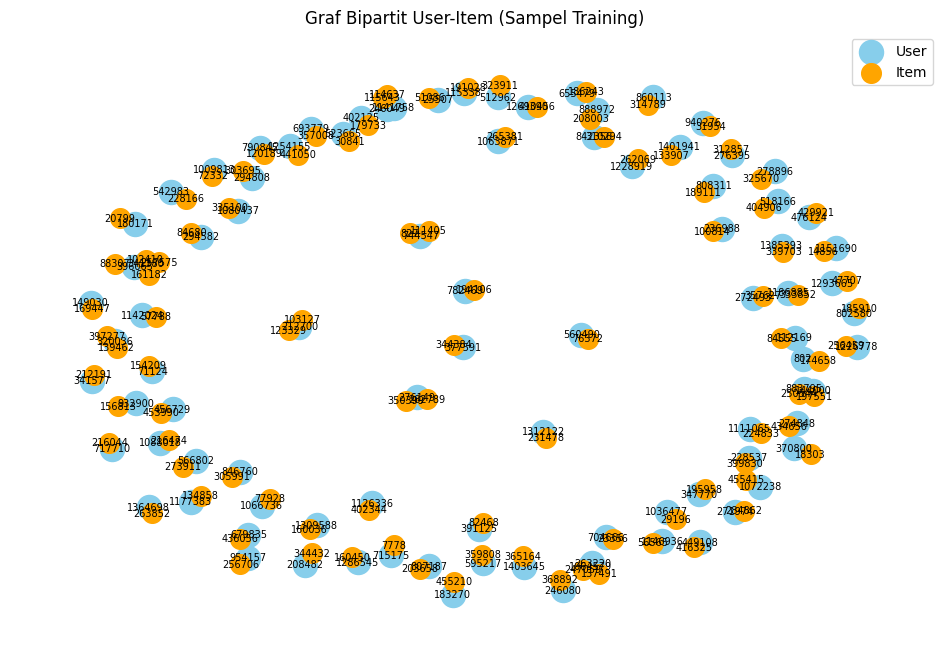

In [35]:
# visualisasi menggunakan MetworkX
import networkx as nx
import matplotlib.pyplot as plt

# Mengambil sebagian data training untuk visualisasi
sample_train = train_df.head(100)

G_user = nx.Graph()

for _, row in sample_train.iterrows():

    if pd.isna(row["visitorid"]) or pd.isna(row["itemid"]):
        continue

    user_node = ("User", int(row["visitorid"]))
    item_node = ("Item", int(row["itemid"]))

    G_user.add_node(user_node, node_type="User")
    G_user.add_node(item_node, node_type="Item")

    G_user.add_edge(
        user_node,
        item_node,
        weight=row["weight"],
        event=row["event"]
    )

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G_user, seed=42)

user_nodes = [
    n for n, d in G_user.nodes(data=True)
    if d["node_type"] == "User"
]

item_nodes = [
    n for n, d in G_user.nodes(data=True)
    if d["node_type"] == "Item"
]

nx.draw_networkx_nodes(
    G_user, pos,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=300,
    label="User"
)

nx.draw_networkx_nodes(
    G_user, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=200,
    label="Item"
)

nx.draw_networkx_edges(
    G_user, pos,
    alpha=0.5
)

nx.draw_networkx_labels(
    G_user, pos,
    labels={
        n: str(n[1])
        for n in G_user.nodes()
    },
    font_size=7
)

plt.title("Graf Bipartit User-Item (Sampel Training)")
plt.legend()
plt.axis("off")
plt.show()

###### Penjelasan
Pembentukan Vector Space Model (VSM) dilakukan dengan mengasumsikan simpul User sebagai representasi pengguna dan simpul Item sebagai representasi objek interaksi. Matriks VSM yang dihasilkan memiliki dua dimensi dengan shape sebesar (159.344, 78.812), yang menunjukkan bahwa terdapat 159.344 User dan 78.812 Item.

Berdasarkan hasil pembentukan matriks, diperoleh 231.919 nilai non-zero dari total 12.558.219.328 elemen. Nilai sparsity sebesar 99,99815% menunjukkan bahwa sebagian besar kombinasi User dan Item belum memiliki interaksi. Kondisi ini memperlihatkan bahwa data interaksi memiliki karakteristik yang sangat sparse.

Visualisasi menggunakan NetworkX dilakukan dengan merepresentasikan User dan Item sebagai dua kelompok simpul yang dihubungkan melalui edge berdasarkan interaksi yang terjadi. Visualisasi tersebut membentuk graf bipartite yang menggambarkan hubungan antara pengguna dan item. Karena ukuran data cukup besar, visualisasi menggunakan sebagian sampel data agar struktur hubungan dapat diamati dengan lebih jelas.

#### 4. Vector Space Modeling(SVM) User

In [37]:
# membuat SVM item
item_user_matrix = user_item_matrix.T.tocsr()

print("VSM Item berhasil dibuat!")
print("Dimensi matriks:", item_user_matrix.ndim)
print("Shape VSM Item:", item_user_matrix.shape)
print("Jumlah Item:", item_user_matrix.shape[0])
print("Jumlah User:", item_user_matrix.shape[1])

VSM Item berhasil dibuat!
Dimensi matriks: 2
Shape VSM Item: (78812, 159344)
Jumlah Item: 78812
Jumlah User: 159344


In [38]:
#menghitung SVM item
total_elements_item = (
    item_user_matrix.shape[0]
    * item_user_matrix.shape[1]
)

zero_elements_item = (
    total_elements_item - item_user_matrix.nnz
)

sparsity_item = (
    zero_elements_item / total_elements_item
)

print("Jumlah seluruh elemen:", total_elements_item)
print("Jumlah elemen nol:", zero_elements_item)
print("Sparsity VSM Item:", sparsity_item)
print("Sparsity (%):", sparsity_item * 100)

Jumlah seluruh elemen: 12558219328
Jumlah elemen nol: 12557987409
Sparsity VSM Item: 0.9999815324932666
Sparsity (%): 99.99815324932666


In [40]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Membuat graf bipartit
G_item = nx.Graph()

# Menggunakan sebagian data training untuk visualisasi
sample_train = train_df.head(100).copy()

for _, row in sample_train.iterrows():

    if pd.isna(row["visitorid"]) or pd.isna(row["itemid"]):
        continue

    user_node = ("User", int(row["visitorid"]))
    item_node = ("Item", int(row["itemid"]))

    # Menambahkan node User dan Item
    G_item.add_node(user_node, node_type="User")
    G_item.add_node(item_node, node_type="Item")

    # Menambahkan hubungan User dengan Item
    G_item.add_edge(
        user_node,
        item_node,
        weight=row["weight"],
        event=row["event"]
    )

print("Graf bipartit berhasil dibuat!")
print("Jumlah Node:", G_item.number_of_nodes())
print("Jumlah Edge:", G_item.number_of_edges())

Graf bipartit berhasil dibuat!
Jumlah Node: 188
Jumlah Edge: 97


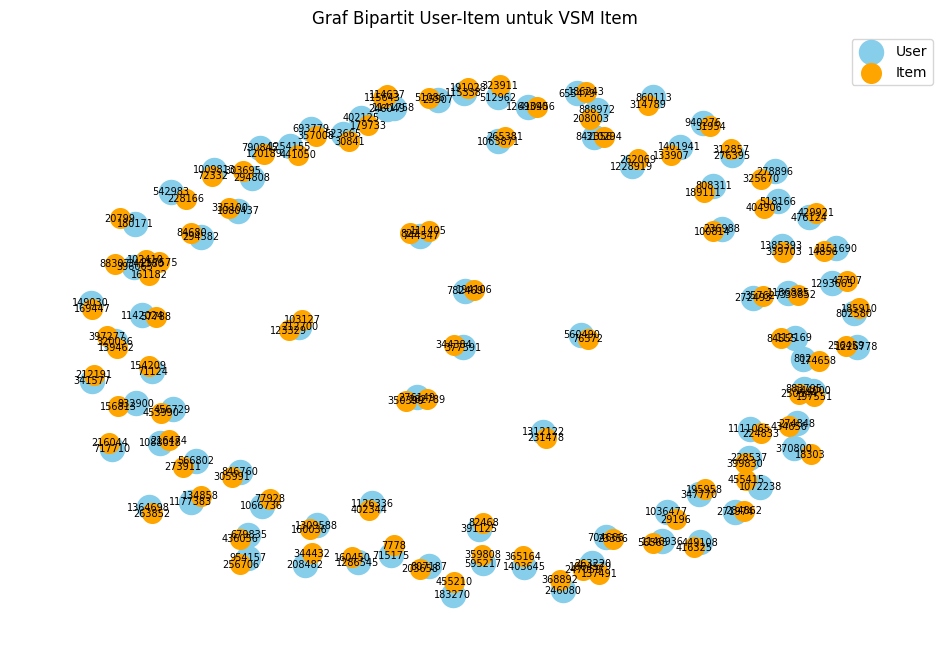

In [41]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    G_item,
    seed=42
)

user_nodes = [
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "User"
]

item_nodes = [
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "Item"
]

nx.draw_networkx_nodes(
    G_item,
    pos,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=300,
    label="User"
)

nx.draw_networkx_nodes(
    G_item,
    pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=200,
    label="Item"
)

nx.draw_networkx_edges(
    G_item,
    pos,
    alpha=0.5
)

nx.draw_networkx_labels(
    G_item,
    pos,
    labels={
        n: str(n[1])
        for n in G_item.nodes()
    },
    font_size=7
)

plt.title("Graf Bipartit User-Item untuk VSM Item")
plt.legend()
plt.axis("off")
plt.show()

In [42]:
# Mengambil seluruh node yang berjenis Item
item_nodes = {
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "Item"
}

# Membentuk proyeksi Item
G_item_projection = nx.bipartite.weighted_projected_graph(
    G_item,
    item_nodes
)

print("=== PROYEKSI ITEM ===")
print("Jumlah Node:", G_item_projection.number_of_nodes())
print("Jumlah Edge:", G_item_projection.number_of_edges())

=== PROYEKSI ITEM ===
Jumlah Node: 97
Jumlah Edge: 7


###### Penjelasan
Pembentukan Vector Space Model (VSM) Item dilakukan dengan mengasumsikan simpul Item sebagai representasi objek yang berinteraksi dengan pengguna. Hasil pembentukan matriks menghasilkan dua dimensi dengan shape sebesar (78.812, 159.344), yang menunjukkan terdapat 78.812 Item dan 159.344 User. Setiap baris merepresentasikan satu Item, sedangkan setiap kolom merepresentasikan User beserta nilai interaksinya terhadap Item tersebut.

Berdasarkan hasil perhitungan, matriks memiliki total 12.558.219.328 elemen, dengan 12.557.987.409 elemen bernilai nol dan 231.919 elemen terisi (non-zero). Nilai sparsity yang diperoleh sebesar 99,99815%, menunjukkan bahwa sebagian besar kombinasi Item dan User tidak memiliki interaksi. Kondisi ini memperlihatkan bahwa matriks VSM Item memiliki karakteristik data yang sangat sparse.

Visualisasi menggunakan NetworkX dilakukan dengan merepresentasikan Item dan User sebagai dua kelompok simpul yang saling terhubung melalui edge berdasarkan interaksi yang terjadi. Graf yang terbentuk merupakan graf bipartite, yaitu graf yang terdiri atas dua kelompok simpul berbeda. Karena ukuran dataset cukup besar, visualisasi menggunakan sampel data agar pola hubungan antara Item dan User dapat diamati dengan lebih jelas.

#### 6. Menentukan proyeksi yang lebih efektif dan efisien

Jumlah node User Projection: 91
Jumlah edge User Projection: 0


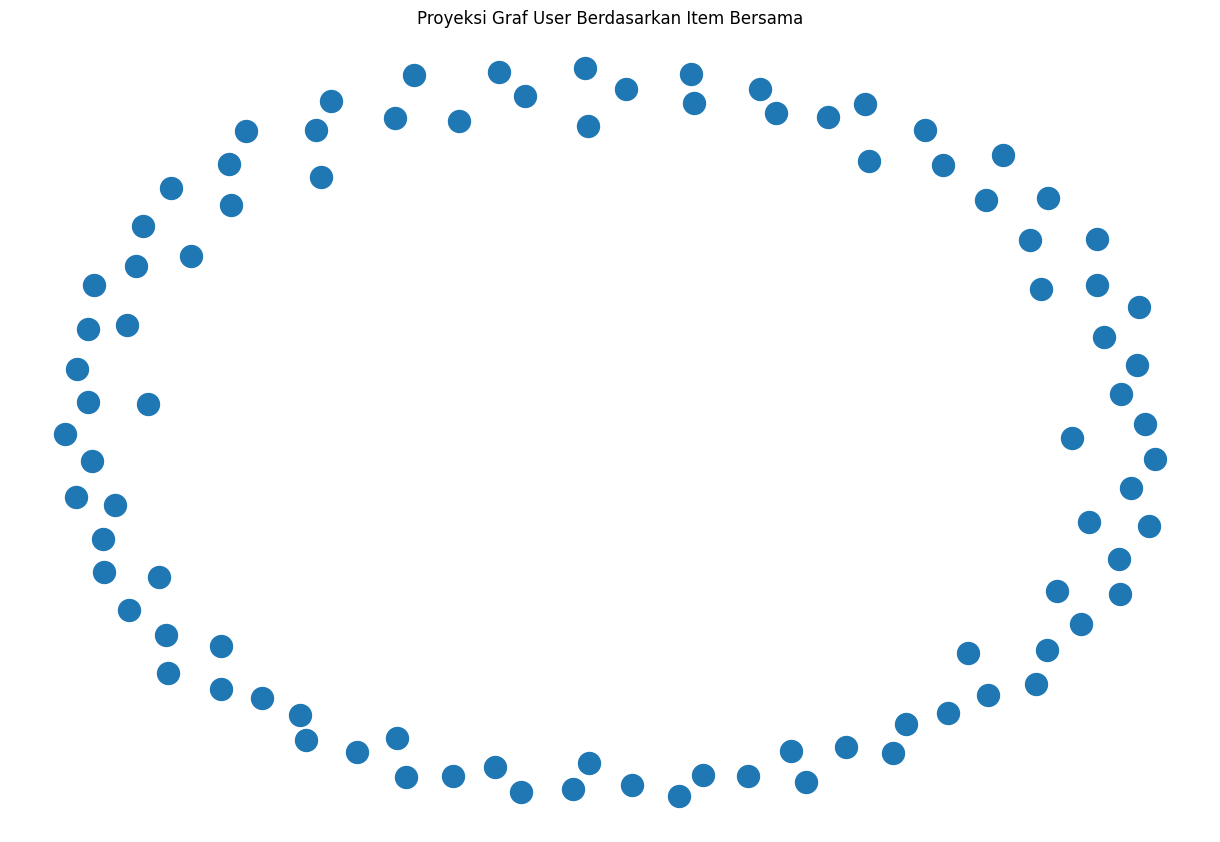

In [43]:
# Proyeksi User dari graf bipartit
user_nodes = {
    n for n, d in G_user.nodes(data=True)
    if d["node_type"] == "User"
}

G_user_projection = nx.bipartite.weighted_projected_graph(
    G_user,
    user_nodes
)

print("Jumlah node User Projection:",
      G_user_projection.number_of_nodes())

print("Jumlah edge User Projection:",
      G_user_projection.number_of_edges())

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    G_user_projection,
    seed=42
)

nx.draw(
    G_user_projection,
    pos,
    with_labels=False,
    node_size=250,
    edge_color="gray",
    width=0.8
)

plt.title("Proyeksi Graf User Berdasarkan Item Bersama")
plt.axis("off")
plt.show()

In [44]:
projection_comparison = pd.DataFrame({
    "Kriteria": [
        "Jumlah Node",
        "Jumlah Edge",
        "Shape VSM",
        "Sparsity (%)"
    ],
    "User Projection": [
        G_user_projection.number_of_nodes(),
        G_user_projection.number_of_edges(),
        str(user_item_matrix.shape),
        sparsity_user * 100
    ],
    "Item Projection": [
        G_item_projection.number_of_nodes(),
        G_item_projection.number_of_edges(),
        str(item_user_matrix.shape),
        sparsity_item * 100
    ]
})

display(projection_comparison)

,Kriteria,User Projection,Item Projection
0,Jumlah Node,91,97
1,Jumlah Edge,0,7
2,Shape VSM,"(159344, 78812)","(78812, 159344)"
3,Sparsity (%),99.998153,99.998153


Berdasarkan hasil eksplorasi User Projection dan Item Projection, dapat disimpulkan bahwa Item Projection lebih efektif dalam membentuk hubungan antar-node dibandingkan User Projection. Hal ini ditunjukkan oleh Item Projection yang menghasilkan 97 node dan 7 edge, sedangkan User Projection menghasilkan 91 node tanpa adanya edge. Keberadaan edge pada Item Projection menunjukkan adanya hubungan antar-item berdasarkan kesamaan pola interaksi pengguna.

Meskipun demikian, kedua proyeksi memiliki nilai sparsity yang sama, yaitu 99,998153%, sehingga keduanya memiliki karakteristik matriks yang sangat sparse. Dari segi representasi, User Projection berfokus pada hubungan antar-pengguna, sedangkan Item Projection berfokus pada hubungan antar-item.

Dengan demikian, Item Projection lebih direkomendasikan untuk eksplorasi hubungan kemiripan item dan pengembangan sistem rekomendasi berbasis item. Namun, hasil ini belum secara langsung membuktikan bahwa Item Projection lebih efisien secara komputasi karena diperlukan pengukuran tambahan seperti waktu eksekusi dan penggunaan memori.

#### 7. Menghitung similarity dari graf yang diproyeksikan menggunakan Python

In [47]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Jumlah User
n_users = user_item_matrix.shape[0]

# Ukuran batch
BATCH_SIZE = 100

similarity_records = []

print("Jumlah User:", n_users)
print("Memulai perhitungan similarity secara bertahap...")

for start in tqdm(range(0, n_users, BATCH_SIZE)):

    end = min(start + BATCH_SIZE, n_users)

    # Mengambil sebagian baris VSM
    batch_matrix = user_item_matrix[start:end]

    # Menghitung similarity batch terhadap seluruh User
    sim_matrix = cosine_similarity(
        batch_matrix,
        user_item_matrix,
        dense_output=True
    )

    # Mengambil dua tetangga terdekat setiap User
    for local_idx in range(end - start):

        global_idx = start + local_idx

        # Mengabaikan User itu sendiri
        sim_matrix[local_idx, global_idx] = -1

        # Mengambil indeks tetangga dengan similarity tertinggi
        top_indices = np.argpartition(
            sim_matrix[local_idx],
            -1
        )[-1:]

        for neighbor_idx in top_indices:

            similarity = sim_matrix[
                local_idx,
                neighbor_idx
            ]

            if similarity > 0:

                similarity_records.append({
                    "user1": int(user_ids[global_idx]),
                    "user2": int(user_ids[neighbor_idx]),
                    "similarity": float(similarity)
                })

    del sim_matrix

print("Perhitungan similarity selesai!")

Jumlah User: 159344
Memulai perhitungan similarity secara bertahap...


100%|██████████| 1594/1594 [59:39<00:00,  2.25s/it] 


Perhitungan similarity selesai!


In [48]:
similarity_df = pd.DataFrame(similarity_records)

# Menghilangkan pasangan terbalik yang sama
similarity_df["pair"] = similarity_df.apply(
    lambda row: tuple(sorted([
        row["user1"],
        row["user2"]
    ])),
    axis=1
)

similarity_df = (
    similarity_df
    .sort_values(
        "similarity",
        ascending=False
    )
    .drop_duplicates("pair")
    .reset_index(drop=True)
)

top5_similarity = similarity_df.head(5)

print("5 Pasangan User dengan Similarity Tertinggi:")
display(
    top5_similarity[
        ["user1", "user2", "similarity"]
    ]
)

5 Pasangan User dengan Similarity Tertinggi:


,user1,user2,similarity
0,358528,815961,1.0
1,659574,131940,1.0
2,331589,126314,1.0
3,469481,410651,1.0
4,900628,863066,1.0


In [49]:
query_save_similarity = """
UNWIND $rows AS row

MATCH (u1:Visitor {visitorid: row.user1})
MATCH (u2:Visitor {visitorid: row.user2})

MERGE (u1)-[r:SIMILAR_TO]->(u2)

SET r.similarity = row.similarity
"""

rows_similarity = top5_similarity[
    ["user1", "user2", "similarity"]
].to_dict("records")

with driver.session(database="neo4j") as session:
    session.run(
        query_save_similarity,
        rows=rows_similarity
    )

print("Lima pasangan similarity berhasil disimpan ke Neo4j!")

Lima pasangan similarity berhasil disimpan ke Neo4j!


#### 7a. mengambil lima pasangan User dengan nilai similarity paling tinggi.

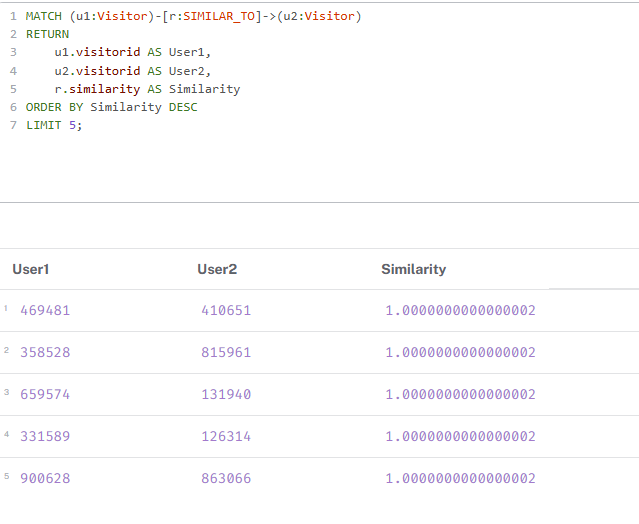

#### 7b. Menampilkan nilai similarity pada graph

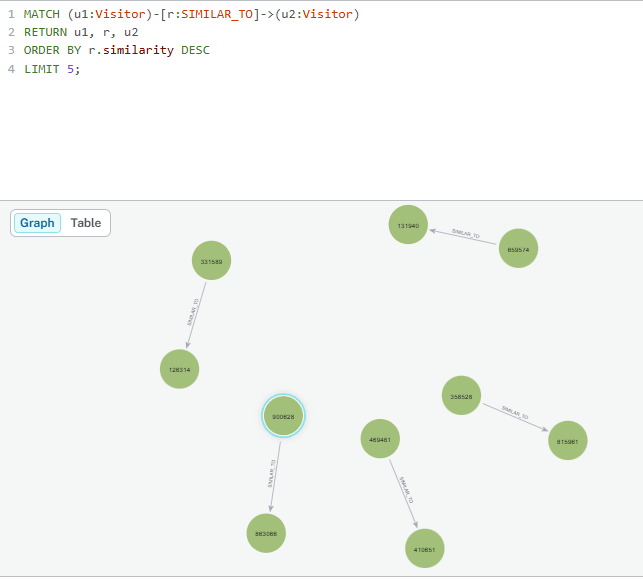

#### 8. Perbandingan sebelum dan sesudah perhitungan similarity
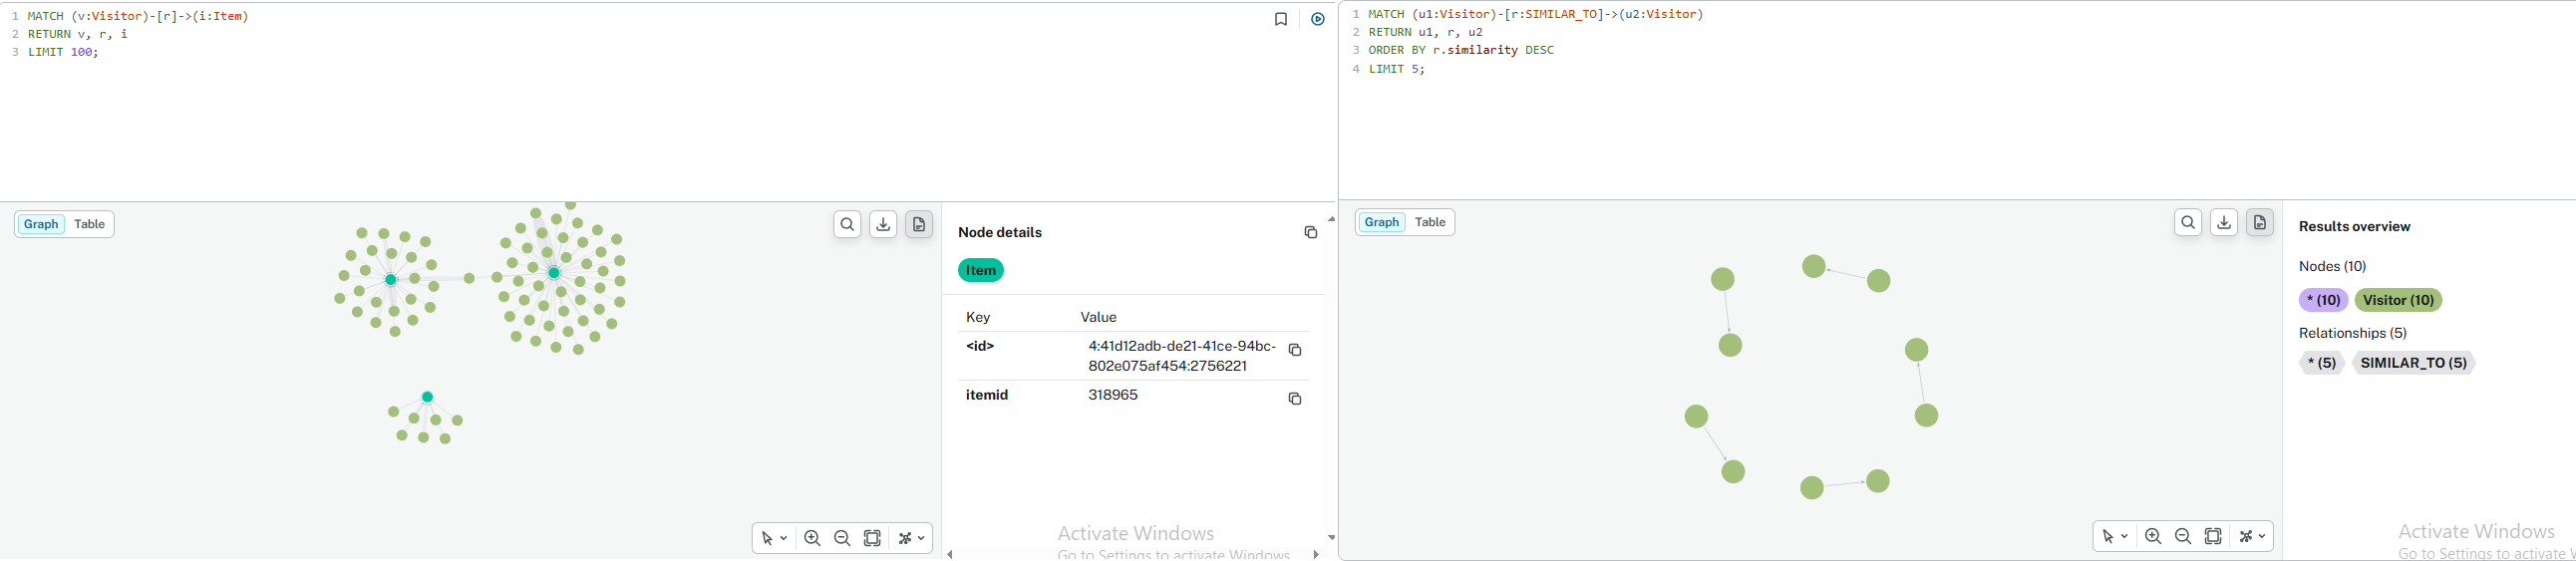

Sebelum perhitungan similarity, graph hanya menunjukkan hubungan antara pengguna dan produk berdasarkan aktivitas seperti melihat produk, menambahkan ke keranjang, dan melakukan transaksi. Setelah similarity dihitung, graph memperoleh hubungan tambahan SIMILAR_TO yang menghubungkan dua pengguna berdasarkan kemiripan pola interaksi. Hubungan tersebut dapat dimanfaatkan untuk mencari pengguna dengan perilaku serupa dalam proses rekomendasi.

## 2.2

#### 1

In [50]:
import numpy as np

random_state = 42

rng = np.random.default_rng(random_state)

selected_index = rng.integers(
    low=0,
    high=len(user_ids)
)

selected_user = int(user_ids[selected_index])

print("Random State:", random_state)
print("User terpilih:", selected_user)

Random State: 42
User terpilih: 1325344


In [51]:
# mencari lima tetanggaan terdekat
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(user_item_matrix)

target_vector = user_item_matrix[selected_index]

distances, indices = knn.kneighbors(
    target_vector,
    n_neighbors=6
)

neighbor_records = []

for distance, index in zip(
    distances[0],
    indices[0]
):

    neighbor_id = int(user_ids[index])

    # Menghilangkan user target
    if neighbor_id == selected_user:
        continue

    similarity = 1 - distance

    neighbor_records.append({
        "visitorid": neighbor_id,
        "distance": float(distance),
        "similarity": float(similarity)
    })

    if len(neighbor_records) == 5:
        break

neighbors_df = pd.DataFrame(neighbor_records)

print("User target:", selected_user)
print("Lima tetangga terdekat:")
display(neighbors_df)

User target: 1325344
Lima tetangga terdekat:


,visitorid,distance,similarity
0,860035,0.000000,1.000000
1,807250,0.000000,1.000000
2,622916,0.770584,0.229416
3,1154007,0.828501,0.171499
4,102438,1.000000,0.000000


In [52]:
# Item yang pernah diinteraksikan oleh user target
target_items = set(
    user_item_matrix[
        selected_index
    ].indices
)

recommendation_scores = {}

# Menghitung skor kandidat dari 5 tetangga
for _, neighbor in neighbors_df.iterrows():

    neighbor_id = neighbor["visitorid"]
    similarity = neighbor["similarity"]

    neighbor_index = user_map[neighbor_id]

    # Mengambil item yang pernah diinteraksikan tetangga
    neighbor_vector = user_item_matrix[neighbor_index]

    interacted_item_indices = neighbor_vector.indices
    interaction_weights = neighbor_vector.data

    for item_index, weight in zip(
        interacted_item_indices,
        interaction_weights
    ):

        # Hanya mengambil item yang belum pernah
        # diinteraksikan oleh user target
        if item_index not in target_items:

            item_id = item_ids[item_index]

            score = similarity * weight

            recommendation_scores[item_id] = (
                recommendation_scores.get(item_id, 0)
                + score
            )

In [53]:
recommendation_df = pd.DataFrame(
    [
        {
            "itemid": item_id,
            "score": score
        }
        for item_id, score in recommendation_scores.items()
    ]
)

recommendation_df = recommendation_df.sort_values(
    "score",
    ascending=False
).reset_index(drop=True)

top3_recommendations = recommendation_df.head(3)

print("User target:", selected_user)
print("Tiga Item yang Direkomendasikan:")

display(top3_recommendations)

User target: 1325344
Tiga Item yang Direkomendasikan:


,itemid,score
0,381542,1.260660
1,457328,0.514496
2,376336,0.342997


Proses rekomendasi dilakukan dengan menggunakan algoritma K-Nearest Neighbors (KNN) dengan nilai K = 5. Lima pengguna yang memiliki kemiripan tertinggi terhadap pengguna target dipilih berdasarkan Cosine Similarity. Selanjutnya, item yang pernah diinteraksikan oleh kelima pengguna yaitu dengan id 381542	, 457328 dan 376336 tersebut dikumpulkan sebagai kandidat rekomendasi. Item yang sudah pernah diinteraksikan oleh pengguna target dikeluarkan. Kandidat kemudian diberi skor berdasarkan nilai similarity dan bobot interaksi, lalu diurutkan untuk memperoleh tiga item dengan skor tertinggi.

#### 2. Menghitung evaluasi hasil rekomendasi

In [54]:
# Mengambil 5 rekomendasi teratas
top5_recommendations = recommendation_df.head(5)

recommended_items = (
    top5_recommendations["itemid"].tolist()
)

# Mengambil item aktual dari test_df
actual_items = set(
    test_df.loc[
        test_df["visitorid"] == selected_user,
        "itemid"
    ].dropna().tolist()
)

# Fungsi HIT@5
def hit_at_5(recommended_items, actual_items):

    recommended_items = set(
        recommended_items[:5]
    )

    return int(
        len(recommended_items.intersection(actual_items)) > 0
    )

hit5 = hit_at_5(
    recommended_items,
    actual_items
)

print("User target:", selected_user)
print("Jumlah item aktual:", len(actual_items))
print("Rekomendasi:", recommended_items)
print("HIT@5:", hit5)

User target: 1325344
Jumlah item aktual: 0
Rekomendasi: [381542, 457328, 376336, 49298, 437250]
HIT@5: 0


In [55]:
import numpy as np

def ndcg_at_5(recommended_items, actual_items):

    recommended_items = recommended_items[:5]
    actual_items = set(actual_items)

    # Menentukan relevansi setiap item
    relevance = [
        1 if item in actual_items else 0
        for item in recommended_items
    ]

    # Menghitung DCG
    dcg = sum(
        rel / np.log2(position + 1)
        for position, rel in enumerate(
            relevance,
            start=1
        )
    )

    # Menghitung IDCG berdasarkan jumlah item relevan
    ideal_relevance = [
        1
    ] * min(len(actual_items), 5)

    idcg = sum(
        rel / np.log2(position + 1)
        for position, rel in enumerate(
            ideal_relevance,
            start=1
        )
    )

    if idcg == 0:
        return 0

    return dcg / idcg


ndcg5 = ndcg_at_5(
    recommended_items,
    actual_items
)

print("NDCG@5:", ndcg5)

NDCG@5: 0


In [56]:
evaluation_result = pd.DataFrame({
    "Metrik": [
        "HIT@5",
        "NDCG@5"
    ],
    "Nilai": [
        hit5,
        ndcg5
    ]
})

print("Hasil Evaluasi Rekomendasi:")
display(evaluation_result)

Hasil Evaluasi Rekomendasi:


,Metrik,Nilai
0,HIT@5,0
1,NDCG@5,0


Berdasarkan hasil evaluasi, diperoleh nilai HIT@5 sebesar 0 dan NDCG@5 sebesar 0. Hasil tersebut menunjukkan bahwa tidak terdapat item dari lima rekomendasi teratas yang sesuai dengan item aktual pengguna pada data testing. Nilai HIT@5 menunjukkan bahwa sistem belum berhasil menghasilkan rekomendasi yang relevan, sedangkan nilai NDCG@5 menunjukkan bahwa belum terdapat item relevan yang dapat dinilai berdasarkan urutan rekomendasi. Dengan demikian, performa rekomendasi pada pengguna yang diuji masih belum optimal. Namun, hasil ini hanya menggambarkan kinerja sistem pada satu pengguna yang dipilih, sehingga belum dapat digunakan untuk menyimpulkan performa sistem secara keseluruhan.